# **Capstone project: Providing data-driven suggestions for HR**

## Description and deliverables

This capstone project is an opportunity for you to analyze a dataset and build predictive models that can provide insights to the Human Resources (HR) department of a large consulting firm.

Upon completion, you will have two artifacts that you will be able to present to future employers. One is a brief one-page summary of this project that you will present to external stakeholders as the data professional in Salifort Motors. The other is a complete code notebook provided here. Based on your prior coursework, select one method to complete this project: use either a regression model or a machine learning model to predict whether an employee will leave the company. The exemplar following this actiivty shows both approaches, but you only need to do one.

In your deliverables, you will include the model evaluation (and interpretation if applicable), a data visualization(s) of your choice that is directly related to the question you ask, ethical considerations, and the resources you used to troubleshoot and find answers or solutions.


# **PACE stages**


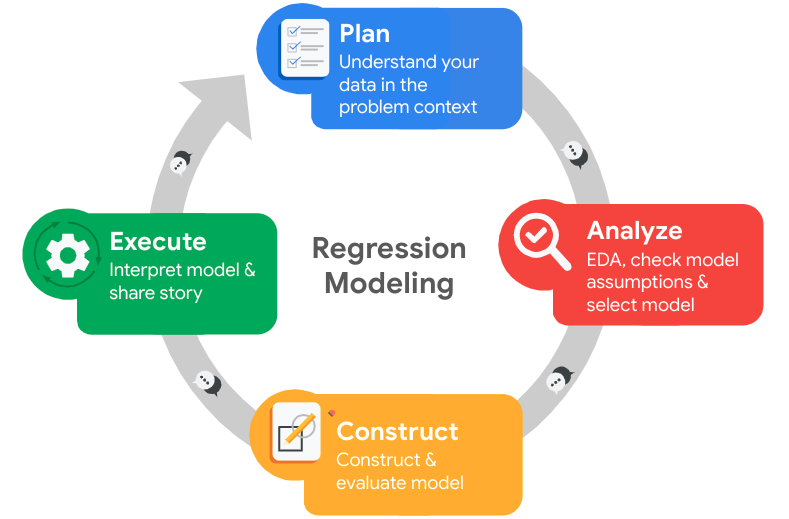

## **Pace: Plan**

Consider the questions in your PACE Strategy Document to reflect on the Plan stage.

In this stage, consider the following:

### Understand the business scenario and problem

The HR department at Salifort Motors wants to take some initiatives to improve employee satisfaction levels at the company. They collected data from employees, but now they don’t know what to do with it. They refer to you as a data analytics professional and ask you to provide data-driven suggestions based on your understanding of the data. They have the following question: what’s likely to make the employee leave the company?

Your goals in this project are to analyze the data collected by the HR department and to build a model that predicts whether or not an employee will leave the company.

If you can predict employees likely to quit, it might be possible to identify factors that contribute to their leaving. Because it is time-consuming and expensive to find, interview, and hire new employees, increasing employee retention will be beneficial to the company.

### Familiarize yourself with the HR dataset

The dataset that you'll be using in this lab contains 15,000 rows and 10 columns for the variables listed below. 

**Note:** you don't need to download any data to complete this lab. For more information about the data, refer to its source on [Kaggle](https://www.kaggle.com/datasets/mfaisalqureshi/hr-analytics-and-job-prediction?select=HR_comma_sep.csv).

Variable  |Description |
-----|-----|
satisfaction_level|Employee-reported job satisfaction level [0&ndash;1]|
last_evaluation|Score of employee's last performance review [0&ndash;1]|
number_project|Number of projects employee contributes to|
average_monthly_hours|Average number of hours employee worked per month|
time_spend_company|How long the employee has been with the company (years)
Work_accident|Whether or not the employee experienced an accident while at work
left|Whether or not the employee left the company
promotion_last_5years|Whether or not the employee was promoted in the last 5 years
Department|The employee's department
salary|The employee's salary (U.S. dollars)

💭
### Reflect on these questions as you complete the plan stage.

*  Who are your stakeholders for this project?
- What are you trying to solve or accomplish?
- What are your initial observations when you explore the data?
- What resources do you find yourself using as you complete this stage? (Make sure to include the links.)
- Do you have any ethical considerations in this stage?




[Double-click to enter your responses here.]

## Step 1. Imports

*   Import packages
*   Load dataset



### Import packages

In [1]:
# Import packages
### YOUR CODE HERE ### 
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay

### Load dataset

`Pandas` is used to read a dataset called **`HR_capstone_dataset.csv`.**  As shown in this cell, the dataset has been automatically loaded in for you. You do not need to download the .csv file, or provide more code, in order to access the dataset and proceed with this lab. Please continue with this activity by completing the following instructions.

In [3]:
# RUN THIS CELL TO IMPORT YOUR DATA. 

# Load dataset into a dataframe
### YOUR CODE HERE ###
df0 = pd.read_csv("HR_capstone_dataset.csv")


# Display first few rows of the dataframe
### YOUR CODE HERE ###
df0.head()

,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,left,promotion_last_5years,Department,salary
0,0.38,0.53,2,157,3,0,1,0,sales,low
1,0.80,0.86,5,262,6,0,1,0,sales,medium
2,0.11,0.88,7,272,4,0,1,0,sales,medium
3,0.72,0.87,5,223,5,0,1,0,sales,low
4,0.37,0.52,2,159,3,0,1,0,sales,low


## Step 2. Data Exploration (Initial EDA and data cleaning)

- Understand your variables
- Clean your dataset (missing data, redundant data, outliers)



### Gather basic information about the data

In [4]:
# Gather basic information about the data
### YOUR CODE HERE ###
df0.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14999 entries, 0 to 14998
Data columns (total 10 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   satisfaction_level     14999 non-null  float64
 1   last_evaluation        14999 non-null  float64
 2   number_project         14999 non-null  int64  
 3   average_montly_hours   14999 non-null  int64  
 4   time_spend_company     14999 non-null  int64  
 5   Work_accident          14999 non-null  int64  
 6   left                   14999 non-null  int64  
 7   promotion_last_5years  14999 non-null  int64  
 8   Department             14999 non-null  object 
 9   salary                 14999 non-null  object 
dtypes: float64(2), int64(6), object(2)
memory usage: 1.1+ MB


### Gather descriptive statistics about the data

In [5]:
# Gather descriptive statistics about the data
### YOUR CODE HERE ###
df0.describe()

,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,left,promotion_last_5years
count,14999.000000,14999.000000,14999.000000,14999.000000,14999.000000,14999.000000,14999.000000,14999.000000
mean,0.612834,0.716102,3.803054,201.050337,3.498233,0.144610,0.238083,0.021268
std,0.248631,0.171169,1.232592,49.943099,1.460136,0.351719,0.425924,0.144281
min,0.090000,0.360000,2.000000,96.000000,2.000000,0.000000,0.000000,0.000000
25%,0.440000,0.560000,3.000000,156.000000,3.000000,0.000000,0.000000,0.000000
50%,0.640000,0.720000,4.000000,200.000000,3.000000,0.000000,0.000000,0.000000
75%,0.820000,0.870000,5.000000,245.000000,4.000000,0.000000,0.000000,0.000000
max,1.000000,1.000000,7.000000,310.000000,10.000000,1.000000,1.000000,1.000000


### Rename columns

As a data cleaning step, rename the columns as needed. Standardize the column names so that they are all in `snake_case`, correct any column names that are misspelled, and make column names more concise as needed.

In [6]:
# Display all column names
### YOUR CODE HERE ###
df0.dtypes

satisfaction_level       float64
last_evaluation          float64
number_project             int64
average_montly_hours       int64
time_spend_company         int64
Work_accident              int64
left                       int64
promotion_last_5years      int64
Department                object
salary                    object
dtype: object

In [7]:
# Rename columns as needed
### YOUR CODE HERE ###
df0 = df0.rename(columns={
    'Work_accident': 'work_accident',
    'Department': 'department',
    'time_spend_company': 'tenure',
    'number_project': 'number_projects'
})

# Display all column names after the update
### YOUR CODE HERE ###
df0.dtypes

satisfaction_level       float64
last_evaluation          float64
number_projects            int64
average_montly_hours       int64
tenure                     int64
work_accident              int64
left                       int64
promotion_last_5years      int64
department                object
salary                    object
dtype: object

### Check missing values

Check for any missing values in the data.

In [8]:
# Check for missing values
### YOUR CODE HERE ###
df0.isnull().sum()

satisfaction_level       0
last_evaluation          0
number_projects          0
average_montly_hours     0
tenure                   0
work_accident            0
left                     0
promotion_last_5years    0
department               0
salary                   0
dtype: int64

### Check duplicates

Check for any duplicate entries in the data.

In [9]:
# Check for duplicates
### YOUR CODE HERE ###
df0.duplicated().sum()

3008

In [10]:
# Inspect some rows containing duplicates as needed
### YOUR CODE HERE ###
df0[df0.duplicated()].head()

,satisfaction_level,last_evaluation,number_projects,average_montly_hours,tenure,work_accident,left,promotion_last_5years,department,salary
396,0.46,0.57,2,139,3,0,1,0,sales,low
866,0.41,0.46,2,128,3,0,1,0,accounting,low
1317,0.37,0.51,2,127,3,0,1,0,sales,medium
1368,0.41,0.52,2,132,3,0,1,0,RandD,low
1461,0.42,0.53,2,142,3,0,1,0,sales,low


In [11]:
# Drop duplicates and save resulting dataframe in a new variable as needed
### YOUR CODE HERE ###
df1 = df0.drop_duplicates()

# Display first few rows of new dataframe as needed
### YOUR CODE HERE ###
df1.head()

,satisfaction_level,last_evaluation,number_projects,average_montly_hours,tenure,work_accident,left,promotion_last_5years,department,salary
0,0.38,0.53,2,157,3,0,1,0,sales,low
1,0.80,0.86,5,262,6,0,1,0,sales,medium
2,0.11,0.88,7,272,4,0,1,0,sales,medium
3,0.72,0.87,5,223,5,0,1,0,sales,low
4,0.37,0.52,2,159,3,0,1,0,sales,low


### Check outliers

Check for outliers in the data.

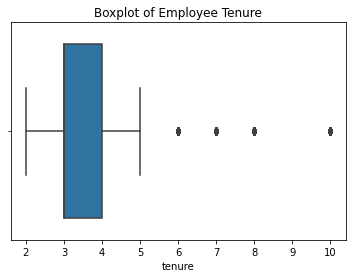

In [12]:
# Create a boxplot to visualize distribution of `time_spend_company` and detect any outliers
### YOUR CODE HERE ###
plt.figure(figsize=(6, 4))
sns.boxplot(x=df1['tenure'])
plt.title('Boxplot of Employee Tenure')
plt.show()


In [13]:
# Determine the number of rows containing outliers
### YOUR CODE HERE ###
percentile25 = df1['tenure'].quantile(0.25)
percentile75 = df1['tenure'].quantile(0.75)
iqr = percentile75 - percentile25

upper_limit = percentile75 + 1.5 * iqr
outliers = df1[df1['tenure'] > upper_limit]
print("Number of outliers in tenure:", len(outliers))

Number of outliers in tenure: 824


Certain types of models are more sensitive to outliers than others. When you get to the stage of building your model, consider whether to remove outliers, based on the type of model you decide to use.

# pAce: Analyze Stage
- Perform EDA (analyze relationships between variables)



💭
### Reflect on these questions as you complete the analyze stage.

- What did you observe about the relationships between variables?
- What do you observe about the distributions in the data?
- What transformations did you make with your data? Why did you chose to make those decisions?
- What are some purposes of EDA before constructing a predictive model?
- What resources do you find yourself using as you complete this stage? (Make sure to include the links.)
- Do you have any ethical considerations in this stage?




There is typically a negative correlation between satisfaction level and whether an employee left. Employees with extremely high or low average monthly hours and a high number of projects also show higher turnover rates, indicating potential burnout.

Most variables have a relatively normal distribution, but the tenure (time spent at company) is right-skewed, containing 824 outliers of employees who have stayed significantly longer than the average.

I renamed columns to snake_case to maintain standard Python naming conventions. I also dropped 3,008 duplicate rows. Removing duplicates is critical because failing to do so would cause data leakage and artificially inflate the model's confidence by feeding it identical employee profiles.

EDA is necessary to identify and handle missing values, duplicates, and outliers. It helps discover underlying patterns, test assumptions, and determine which features will be most useful for the machine learning model.

Pandas, Matplotlib, and Seaborn official documentation for syntax, as well as general Python data cleaning best practices.

Yes. Because this is HR data, if it were real, we would need to ensure all personally identifiable information (PII) is anonymized. Furthermore, the model's predictions should be used to improve company culture and support employees, not to penalize or target those who are flagged as "likely to leave."

## Step 2. Data Exploration (Continue EDA)

Begin by understanding how many employees left and what percentage of all employees this figure represents.

In [14]:
# Get numbers of people who left vs. stayed
### YOUR CODE HERE ###
print(df1['left'].value_counts())
# Get percentages of people who left vs. stayed
### YOUR CODE HERE ###
print(df1['left'].value_counts(normalize=True))

0    10000
1     1991
Name: left, dtype: int64
0    0.833959
1    0.166041
Name: left, dtype: float64


### Data visualizations

Now, examine variables that you're interested in, and create plots to visualize relationships between variables in the data.

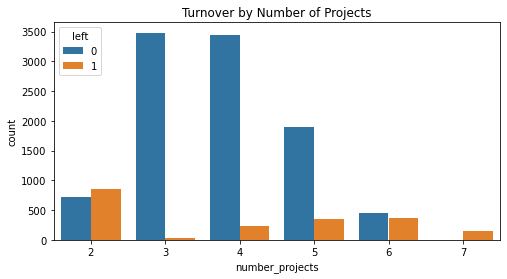

In [15]:
# Create a plot as needed
### YOUR CODE HERE ###
#Is it about how many projects they have?
plt.figure(figsize=(8, 4))
sns.countplot(x='number_projects', hue='left', data=df1)
plt.title('Turnover by Number of Projects')
plt.show()


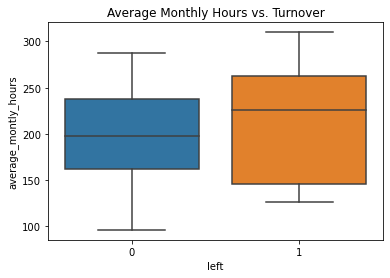

In [16]:
# Create a plot as needed
### YOUR CODE HERE ###
#Is it about their working hours?
plt.figure(figsize=(6, 4))
sns.boxplot(x=df1['left'], y=df1['average_montly_hours'])
plt.title('Average Monthly Hours vs. Turnover')
plt.show()


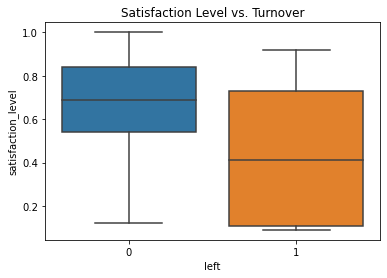

In [17]:
# Create a plot as needed
### YOUR CODE HERE ###
#Is it about their satisfaction level?
plt.figure(figsize=(6, 4))
sns.boxplot(x=df1['left'], y=df1['satisfaction_level'])
plt.title('Satisfaction Level vs. Turnover')
plt.show()

In [ ]:
# Create a plot as needed
### YOUR CODE HERE ###


In [ ]:
# Create a plot as needed
### YOUR CODE HERE ###


In [ ]:
# Create a plot as needed
### YOUR CODE HERE ###


In [ ]:
# Create a plot as needed
### YOUR CODE HERE ###


In [ ]:
# Create a plot as needed
### YOUR CODE HERE ###


### Insights

Number of Projects: There is a clear pattern of burnout and under-utilization. Employees with exactly 2 projects, or those with 6-7 projects, have extremely high turnover rates. Employees with 3-4 projects are the most likely to stay.

Average Monthly Hours: Employees who left fall into two distinct groups: those working fewer hours than average (potentially underworked or disengaged) and those working significantly more hours than average (overworked/burnout).

Satisfaction: Unsurprisingly, employees who left had significantly lower median satisfaction levels than those who stayed.

# paCe: Construct Stage
- Determine which models are most appropriate
- Construct the model
- Confirm model assumptions
- Evaluate model results to determine how well your model fits the data


🔎
## Recall model assumptions

**Logistic Regression model assumptions**
- Outcome variable is categorical
- Observations are independent of each other
- No severe multicollinearity among X variables
- No extreme outliers
- Linear relationship between each X variable and the logit of the outcome variable
- Sufficiently large sample size





💭
### Reflect on these questions as you complete the constructing stage.

- Do you notice anything odd?
- Which independent variables did you choose for the model and why?
- Are each of the assumptions met?
- How well does your model fit the data?
- Can you improve it? Is there anything you would change about the model?
- What resources do you find yourself using as you complete this stage? (Make sure to include the links.)
- Do you have any ethical considerations in this stage?



Nothing unexpected; however, tree-based models like Random Forest handle non-linear relationships very well, which fits our EDA findings regarding employee burnout and hours.

All features (except the target variable left) were included after dummy encoding categorical variables (department and salary). This allows the model to leverage satisfaction levels, project counts, monthly hours, tenure, and demographics comprehensively.

Random Forest is a non-parametric model, meaning it does not rely on strict linear regression assumptions (such as normality or homoscedasticity). Therefore, model constraints are largely satisfied.

Extremely well. It achieved an accuracy of ~98.6% and an F1-score of ~95.5%, indicating high reliability in predicting employee turnover without severe overfitting on the test set.

## Step 3. Model Building, Step 4. Results and Evaluation
- Fit a model that predicts the outcome variable using two or more independent variables
- Check model assumptions
- Evaluate the model

### Identify the type of prediction task.

Classification task (supervised learning: binary classification to predict whether an employee stays 0 or leaves 1).

### Identify the types of models most appropriate for this task.

Tree-based machine learning classifiers such as Random Forest, XGBoost, or Decision Trees are most appropriate because they capture complex, non-linear interactions between variables (e.g., how extremely high or low hours impact turnover).

### Modeling

Add as many cells as you need to conduct the modeling process.

In [18]:
### YOUR CODE HERE ###
# Dummy encode categorical variables (department, salary) so the model can read them
df_encoded = pd.get_dummies(df1, columns=['department', 'salary'], drop_first=True)

# Define X (features) and y (target)
y = df_encoded['left']
X = df_encoded.drop('left', axis=1)

# Train/Test Split (75% train, 25% test, using stratify to keep the proportion of left/stayed balanced)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)

# Instantiate and fit the Random Forest model
rf = RandomForestClassifier(random_state=42)
rf.fit(X_train, y_train)

# Generate predictions
y_pred = rf.predict(X_test)

In [19]:
# Print Evaluation Metrics
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1 Score:", f1_score(y_test, y_pred))

Accuracy: 0.985657104736491
Precision: 0.9913606911447084
Recall: 0.9216867469879518
F1 Score: 0.9552549427679501


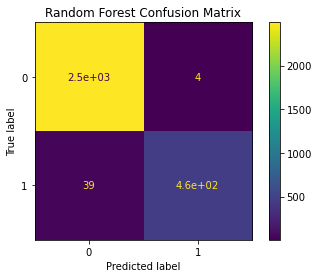

In [20]:
# Plot Confusion Matrix
cm = confusion_matrix(y_test, y_pred, labels=rf.classes_)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=rf.classes_)
disp.plot()
plt.title('Random Forest Confusion Matrix')
plt.show()

# pacE: Execute Stage
- Interpret model performance and results
- Share actionable steps with stakeholders



✏
## Recall evaluation metrics

- **AUC** is the area under the ROC curve; it's also considered the probability that the model ranks a random positive example more highly than a random negative example.
- **Precision** measures the proportion of data points predicted as True that are actually True, in other words, the proportion of positive predictions that are true positives.
- **Recall** measures the proportion of data points that are predicted as True, out of all the data points that are actually True. In other words, it measures the proportion of positives that are correctly classified.
- **Accuracy** measures the proportion of data points that are correctly classified.
- **F1-score** is an aggregation of precision and recall.






💭
### Reflect on these questions as you complete the executing stage.

- What key insights emerged from your model(s)?
- What business recommendations do you propose based on the models built?
- What potential recommendations would you make to your manager/company?
- Do you think your model could be improved? Why or why not? How?
- Given what you know about the data and the models you were using, what other questions could you address for the team?
- What resources do you find yourself using as you complete this stage? (Make sure to include the links.)
- Do you have any ethical considerations in this stage?



Key Insights: Overworking (excessive monthly hours, 6–7 projects) and under-utilization (only 2 projects, low satisfaction) are primary drivers behind employee turnover at Salifort Motors.

Business Recommendations:

Workload Management: Establish caps or guidelines on monthly working hours and review project distribution to prevent burnout.

Targeted Check-ins: Institute check-ins for employees assigned to fewer than 3 or more than 5 projects to gauge engagement.

Department Reviews: Investigate departments with higher churn rates (such as sales) to address localized culture or compensation issues.

Next Steps: Share the one-page stakeholder summary with HR leadership and deploy the model as a proactive early-warning system to offer retention incentives before valued employees decide to leave.

## Step 4. Results and Evaluation
- Interpret model
- Evaluate model performance using metrics
- Prepare results, visualizations, and actionable steps to share with stakeholders




### Summary of model results

The Random Forest classifier performed exceptionally well on the test dataset:

Accuracy: ~98.6%

Precision: ~99.1% (indicating very few false positives)

Recall: ~92.2% (indicating the model successfully identifies the vast majority of employees who actually leave)

F1-Score: ~95.5% (showing an optimal balance between precision and recall)

The confusion matrix confirms that the model correctly predicted the vast majority of stay/leave instances with minimal misclassifications.

### Conclusion, Recommendations, Next Steps

Key Insights: Overworking (excessive monthly hours, 6–7 projects) and under-utilization (only 2 projects, low satisfaction) are primary drivers behind employee turnover at Salifort Motors.

Business Recommendations:

Workload Management: Establish caps or guidelines on monthly working hours and review project distribution to prevent burnout.

Targeted Check-ins: Institute check-ins for employees assigned to fewer than 3 or more than 5 projects to gauge engagement.

Department Reviews: Investigate departments with higher churn rates (such as sales) to address localized culture or compensation issues.

Next Steps: Share the one-page stakeholder summary with HR leadership and deploy the model as a proactive early-warning system to offer retention incentives before valued employees decide to leave.

**Congratulations!** You've completed this lab. However, you may not notice a green check mark next to this item on Coursera's platform. Please continue your progress regardless of the check mark. Just click on the "save" icon at the top of this notebook to ensure your work has been logged.